# Finite State Machines for Industrial Sequencing

`05_fsm` | level 2 | experiment id(s): `exp_05_fsm_motor_starter`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 2 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Write a motor-starter sequence as a Moore state machine with an explicit transition table.
- Check a machine structurally: unreachable states, deadlock states, and whether every state can
  reach a safe state.
- Verify the implementation against an independent `if/elif` implementation on 20 000 random
  events, and verify safety properties by exhaustive enumeration of the table.
- Run timed scenarios (normal run, start failure, overload, emergency stop) and compare the state
  sequence and entry times with a hand-derived expectation.

## 2. Real-World Engineering Problem

A direct-on-line motor starter must start only on request, stop on request, trip on overload,
trip when the motor does not confirm running within a time limit, and drop the contactor
immediately on an emergency stop. After an emergency stop the machine must not restart by itself.
Written as scattered `if` statements these rules are hard to review; as a state machine the
behaviour is one table that can be checked mechanically.

## 3. Research Background

The machine whose output depends on the current state only is attributed to Moore (1956).
Statecharts (Harel, 1987) add hierarchy and concurrency to avoid the state explosion of flat
machines. This notebook uses only the flat Moore form. IEC 61131-3 Sequential Function Chart is
the PLC-language counterpart and is not implemented here.

## 4. Research Literature

Both sources are cited for the definition and for the limits of the flat form. No numerical result
is taken from them.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| moore1956 | Moore, E. F. (1956). Gedanken-experiments on sequential machines. Automata Studies (Annals of Mathematics Studies 34), ed. C. E. Shannon and J. McCarthy, Princeton University Press, 129-153. | Defines the machine whose output depends on the state only (Moore machine). | Theory of state identification experiments, not a control implementation guide. | verified (2026-11-25, web search of publisher/index/library record). Bibliographic record and a facsimile of the chapter agree on title, editors, series and pages. |
| harel1987 | Harel, D. (1987). Statecharts: a visual formalism for complex systems. Science of Computer Programming, 8(3), 231-274. doi:10.1016/0167-6423(87)90035-9. | Hierarchy, concurrency and broadcast extensions to flat state machines. | Specification formalism; flat machines in this repository do not use these extensions. | verified (2026-11-25, web search of publisher/index/library record). Index record and a facsimile of the first page agree on journal, volume, pages and DOI. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

A deterministic Moore machine is $M=(S,s_0,E,\delta,\lambda)$ with states $S$, initial state
$s_0$, events $E$, a **partial** transition function $\delta:S\times E\to S$ and an output
function $\lambda:S\to O$ that depends on the state only.

- An event with $(s,e)\notin\mathrm{dom}\,\delta$ is **dropped** (and recorded).
- State $s$ is **reachable** if some event sequence from $s_0$ ends in $s$: breadth-first search on
  the graph of $\delta$.
- State $s$ is a **deadlock** if every transition out of $s$ returns to $s$ or none exists.
- **Table completeness** $=|\mathrm{dom}\,\delta|/(|S||E|)$.
- A safety property of the form "$\lambda(s)$ has a property for all reachable $s$" is checked by
  enumerating $S$; a property of the form "event $e$ always leads to $s^*$" is checked by
  enumerating $\mathrm{dom}\,\delta$.

## 6. System Modeling

Motor starter with six states (`IDLE`, `STARTING`, `RUNNING`, `STOPPING`, `FAULT`, `ESTOP`) and
nine events (`start`, `run_fb`, `stop`, `stopped_fb`, `overload`, `timeout`, `reset`, `estop`,
`estop_release`). The motor is modelled only by two delays: it confirms running 1.5 s after
the contactor closes and confirms stopped 3.0 s after it opens. Timeouts are 5 s in `STARTING`
and 10 s in `STOPPING`. Scan period 0.1 s. All values are illustrative.

## 7. Dataset and Measurement Data

No dataset. Event sequences for fuzzing come from a seeded pseudo-random generator
(seed 20261125); scenarios are scripted by hand.

## 8. Algorithm Architecture

Architecture: `FSM` (transition table, outputs, structural analysis) is driven by a small
scan loop that (1) applies scripted external events, (2) generates internal events (`run_fb`,
`stopped_fb`, `timeout`) from per-state step counters, and (3) records state and outputs. At most
one event is fired per scan, external events first.

## 9. Algorithm Implementation

In [2]:
from control_lab.controllers import FSM
from control_lab.experiments import ExperimentRecord, check, save_figure

EXP = "exp_05_fsm_motor_starter"
SEED = 20261125
DT = 0.1

TABLE = {
    ("IDLE", "start"): "STARTING", ("IDLE", "estop"): "ESTOP",
    ("STARTING", "run_fb"): "RUNNING", ("STARTING", "timeout"): "FAULT",
    ("STARTING", "overload"): "FAULT", ("STARTING", "stop"): "IDLE", ("STARTING", "estop"): "ESTOP",
    ("RUNNING", "stop"): "STOPPING", ("RUNNING", "overload"): "FAULT", ("RUNNING", "estop"): "ESTOP",
    ("STOPPING", "stopped_fb"): "IDLE", ("STOPPING", "timeout"): "FAULT",
    ("STOPPING", "overload"): "FAULT", ("STOPPING", "estop"): "ESTOP",
    ("FAULT", "reset"): "IDLE", ("FAULT", "estop"): "ESTOP",
    ("ESTOP", "estop_release"): "FAULT",
}
OUTPUTS = {
    "IDLE": {"contactor": 0, "green": 0, "red": 0},
    "STARTING": {"contactor": 1, "green": 0, "red": 0},
    "RUNNING": {"contactor": 1, "green": 1, "red": 0},
    "STOPPING": {"contactor": 0, "green": 0, "red": 0},
    "FAULT": {"contactor": 0, "green": 0, "red": 1},
    "ESTOP": {"contactor": 0, "green": 0, "red": 1},
}
EVENTS = ["start", "run_fb", "stop", "stopped_fb", "overload", "timeout", "reset", "estop", "estop_release"]

def make_fsm(table=TABLE):
    return FSM("IDLE", table, {s: dict(o) for s, o in OUTPUTS.items()})

def ref_step(state, ev):
    # independent implementation written as nested if/elif, not from the table
    if state == "IDLE":
        if ev == "start": return "STARTING"
        if ev == "estop": return "ESTOP"
    elif state == "STARTING":
        if ev == "run_fb": return "RUNNING"
        if ev in ("timeout", "overload"): return "FAULT"
        if ev == "stop": return "IDLE"
        if ev == "estop": return "ESTOP"
    elif state == "RUNNING":
        if ev == "stop": return "STOPPING"
        if ev == "overload": return "FAULT"
        if ev == "estop": return "ESTOP"
    elif state == "STOPPING":
        if ev == "stopped_fb": return "IDLE"
        if ev in ("timeout", "overload"): return "FAULT"
        if ev == "estop": return "ESTOP"
    elif state == "FAULT":
        if ev == "reset": return "IDLE"
        if ev == "estop": return "ESTOP"
    elif state == "ESTOP":
        if ev == "estop_release": return "FAULT"
    return None

FB_RUN, FB_STOP, T_START, T_STOP = 15, 30, 50, 100   # scan counts: 1.5 s, 3.0 s, 5 s, 10 s

def simulate(script, t_end, motor_fails=False):
    fsm = make_fsm()
    ext = {}
    for ts, ev in script:
        ext.setdefault(int(round(ts / DT)), []).append(ev)
    n = int(round(t_end / DT))
    n_in, prev = 0, fsm.state
    entries, trace = [(0.0, fsm.state)], []
    for k in range(n + 1):
        n_in += 1          # scans since entry; entry scan is 0
        fired = False
        for ev in ext.get(k, []):
            fired = fsm.fire(ev, k * DT) or fired
        if not fired:
            s = fsm.state
            if s == "STARTING" and not motor_fails and n_in >= FB_RUN:
                fsm.fire("run_fb", k * DT)
            elif s == "STARTING" and n_in >= T_START:
                fsm.fire("timeout", k * DT)
            elif s == "STOPPING" and n_in >= FB_STOP:
                fsm.fire("stopped_fb", k * DT)
            elif s == "STOPPING" and n_in >= T_STOP:
                fsm.fire("timeout", k * DT)
        if fsm.state != prev:
            entries.append((round(k * DT, 1), fsm.state)); prev = fsm.state; n_in = 0
        trace.append((k * DT, fsm.state, fsm.output("contactor"), fsm.output("red")))
    return {"entries": entries, "trace": trace, "dropped": [(round(t, 1), s, e) for t, s, e in fsm.dropped]}

`TABLE` is the single source of behaviour; `ref_step` re-implements it without a table so the two can
be compared. `simulate` is the scan loop of section 8.

## 10. Simulation and Numerical Analysis

Three analyses: structural checks on the machine and on two deliberately broken machines, fuzzing
against the reference implementation, and four timed scenarios.

## 11. Experimental Validation

Level: **software simulation**. Independent references: the `if/elif` implementation, the hand-derived
state sequences and entry times, and exhaustive enumeration of the table. No PLC or contactor was
used, so nothing here is hardware validation.

## 12. Performance Evaluation

In [3]:
checks = []
fsm = make_fsm()

# 1. structural checks on the intended machine
unreach, dead = fsm.unreachable_states(), fsm.deadlock_states()
cannot_idle = [s for s in fsm.states if not fsm.can_reach(s, "IDLE")]
checks.append(check("intended machine: no unreachable and no deadlock states", not unreach and not dead, f"unreachable={sorted(unreach)}, deadlock={sorted(dead)}"))
checks.append(check("every state can reach IDLE", not cannot_idle, f"cannot reach IDLE: {cannot_idle}"))

# 2. the checker detects deliberately broken machines
bad = dict(TABLE)
bad[("RUNNING", "jam")] = "LATCHED"      # LATCHED has no way out
bad[("ORPHAN", "start")] = "IDLE"        # ORPHAN has no way in
bfsm = FSM("IDLE", bad, {})
checks.append(check("checker finds the planted unreachable state", bfsm.unreachable_states() == {"ORPHAN"}, str(bfsm.unreachable_states())))
checks.append(check("checker finds the planted deadlock state", bfsm.deadlock_states() == {"LATCHED"}, str(bfsm.deadlock_states())))

# 3. safety properties by enumeration
reach = fsm.reachable_from("IDLE")
safe_off = all(OUTPUTS[s]["contactor"] == 0 for s in ("IDLE", "STOPPING", "FAULT", "ESTOP"))
checks.append(check("contactor is open in IDLE, STOPPING, FAULT, ESTOP", safe_off and reach == set(fsm.states), "enumerated over all reachable states"))
estop_all = all(TABLE.get((s, "estop")) == "ESTOP" for s in fsm.states if s != "ESTOP")
checks.append(check("estop leads to ESTOP from every other state in one step", estop_all, "enumerated over all states"))
checks.append(check("ESTOP exits only to FAULT (no automatic restart)", fsm.successors("ESTOP") == {"FAULT"}, str(fsm.successors("ESTOP"))))
into_starting = {(s, e) for (s, e), n in TABLE.items() if n == "STARTING"}
into_running = {(s, e) for (s, e), n in TABLE.items() if n == "RUNNING"}
checks.append(check("contactor-closed states entered only by start from IDLE and run_fb from STARTING", into_starting == {("IDLE", "start")} and into_running == {("STARTING", "run_fb")}, f"{into_starting}, {into_running}"))

# 4. fuzzing against the independent implementation
rng = np.random.default_rng(SEED)
mismatch, n_events, n_dropped_fsm, n_dropped_ref = 0, 0, 0, 0
for _ in range(10):
    f = make_fsm(); s_ref = "IDLE"
    for ev in rng.choice(EVENTS, size=2000):
        taken = f.fire(str(ev)); nxt = ref_step(s_ref, str(ev))
        n_events += 1
        if nxt is None:
            n_dropped_ref += 1
        else:
            s_ref = nxt
        if taken != (nxt is not None) or f.state != s_ref:
            mismatch += 1
    n_dropped_fsm += len(f.dropped)
checks.append(check("FSM equals the if/elif reference on 20 000 random events", mismatch == 0 and n_dropped_fsm == n_dropped_ref, f"mismatches={mismatch}, dropped fsm={n_dropped_fsm}, ref={n_dropped_ref}"))
completeness = len(TABLE) / (len(fsm.states) * len(EVENTS))
print(f"transitions defined: {len(TABLE)} of {len(fsm.states) * len(EVENTS)} ({completeness:.1%}); random events dropped: {n_dropped_fsm / n_events:.1%}")

# 5. timed scenarios against hand-derived expectations
SCEN = {
    "A normal run": (dict(script=[(1.0, "start"), (10.0, "stop")], t_end=16.0),
                    [(0.0, "IDLE"), (1.0, "STARTING"), (2.5, "RUNNING"), (10.0, "STOPPING"), (13.0, "IDLE")], []),
    "B start failure": (dict(script=[(1.0, "start"), (20.0, "reset")], t_end=24.0, motor_fails=True),
                       [(0.0, "IDLE"), (1.0, "STARTING"), (6.0, "FAULT"), (20.0, "IDLE")], []),
    "C overload": (dict(script=[(1.0, "start"), (8.0, "overload"), (9.0, "start"), (12.0, "reset")], t_end=16.0),
                  [(0.0, "IDLE"), (1.0, "STARTING"), (2.5, "RUNNING"), (8.0, "FAULT"), (12.0, "IDLE")], [(9.0, "FAULT", "start")]),
    "D emergency stop": (dict(script=[(1.0, "start"), (6.0, "estop"), (7.0, "start"), (9.0, "estop_release"), (10.0, "start"), (12.0, "reset")], t_end=16.0),
                        [(0.0, "IDLE"), (1.0, "STARTING"), (2.5, "RUNNING"), (6.0, "ESTOP"), (9.0, "FAULT"), (12.0, "IDLE")],
                        [(7.0, "ESTOP", "start"), (10.0, "FAULT", "start")]),
}
runs, scen_metrics = {}, {}
for name, (kw, exp_entries, exp_dropped) in SCEN.items():
    r = simulate(**kw); runs[name] = r
    ok = r["entries"] == exp_entries and r["dropped"] == exp_dropped
    unsafe = [t for t, s, c, red in r["trace"] if s in ("FAULT", "ESTOP") and c == 1]
    checks.append(check(f"scenario {name}: state sequence, entry times and dropped events as derived", ok, f"got {r['entries']}, dropped {r['dropped']}"))
    checks.append(check(f"scenario {name}: contactor never closed in FAULT or ESTOP", not unsafe, f"violations at {unsafe[:3]}"))
    scen_metrics[name] = {"entries": r["entries"], "dropped_events": r["dropped"]}
for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")
metrics = {"states": len(fsm.states), "events": len(EVENTS), "transitions_defined": len(TABLE),
           "table_completeness": completeness, "random_events": n_events,
           "random_events_dropped_fraction": n_dropped_fsm / n_events, "fuzz_mismatches": mismatch,
           "scenarios": scen_metrics}

transitions defined: 17 of 54 (31.5%); random events dropped: 82.3%
17 of 17 checks passed


Each check compares against something other than the code under test: the planted-fault machines
must be detected, the table must agree with the `if/elif` version, and the scenarios must match
sequences derived by hand from the delays in section 6.

## 13. Visualization and Interpretation

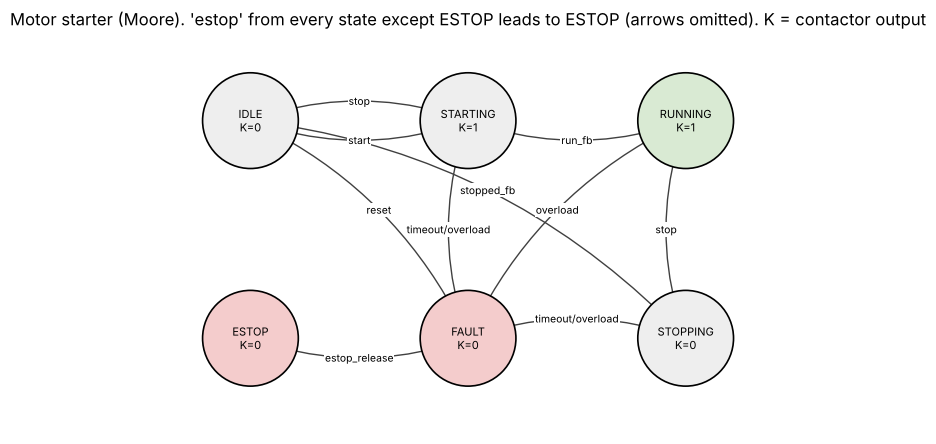

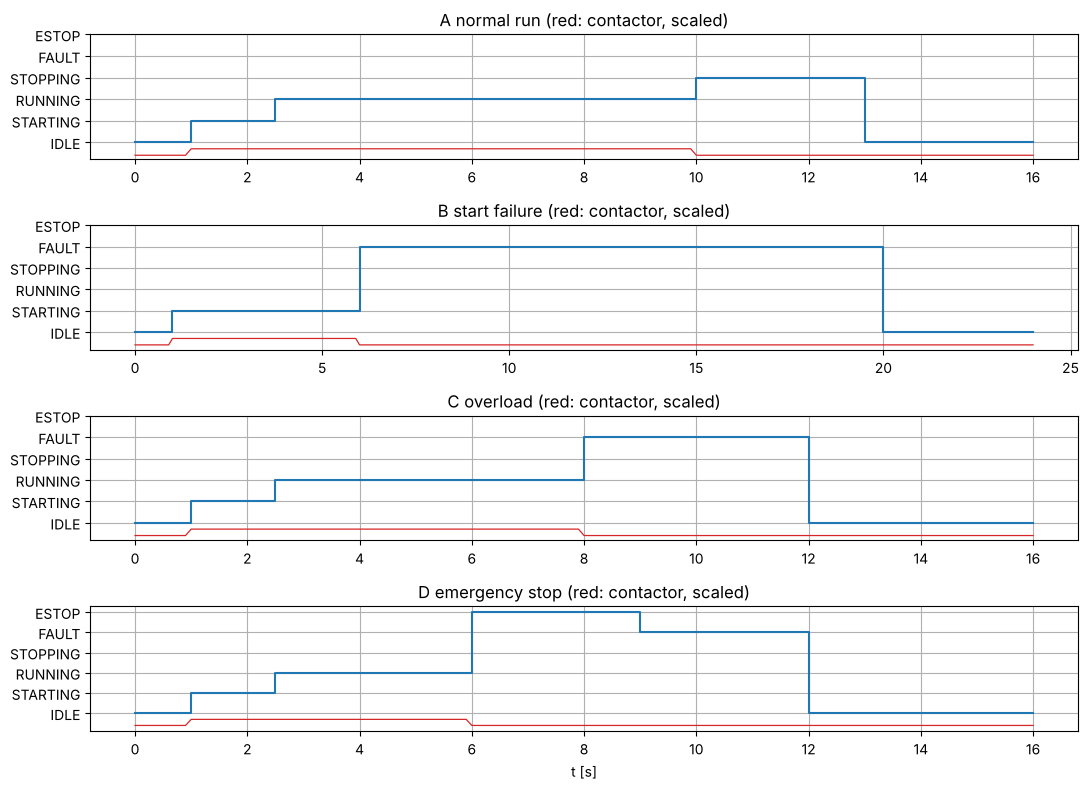

In [4]:
import matplotlib.patches as mp
pos = {"IDLE": (0, 1), "STARTING": (2.5, 1), "RUNNING": (5, 1), "STOPPING": (5, -1.5), "FAULT": (2.5, -1.5), "ESTOP": (0, -1.5)}
fig, ax = plt.subplots(figsize=(11, 5.2))
groups = {}
for (s, e), n in TABLE.items():
    if e != "estop":
        groups.setdefault((s, n), []).append(e)
for (s, n), evs in groups.items():
    (x0, y0), (x1, y1) = pos[s], pos[n]
    ax.add_patch(mp.FancyArrowPatch((x0, y0), (x1, y1), connectionstyle="arc3,rad=0.18", arrowstyle="-|>", mutation_scale=12, shrinkA=22, shrinkB=22, color="0.25", lw=1))
    mx, my = (x0 + x1) / 2, (y0 + y1) / 2
    dx, dy = x1 - x0, y1 - y0
    ax.text(mx + 0.18 * dy * 0.5, my - 0.18 * dx * 0.5, "/".join(evs), fontsize=7.5, ha="center", va="center", bbox=dict(fc="white", ec="none", pad=0.6))
for s, (x, y) in pos.items():
    col = "#f4cccc" if OUTPUTS[s]["red"] else ("#d9ead3" if OUTPUTS[s]["green"] else "#eeeeee")
    ax.add_patch(mp.Circle((x, y), 0.55, fc=col, ec="k", lw=1.2))
    ax.text(x, y, s + chr(10) + "K=" + str(OUTPUTS[s]["contactor"]), ha="center", va="center", fontsize=8)
ax.set(xlim=(-1, 6), ylim=(-2.6, 2.0), aspect="equal", title="Motor starter (Moore). 'estop' from every state except ESTOP leads to ESTOP (arrows omitted). K = contactor output")
ax.axis("off")
figs = [save_figure(fig, EXP, "state_diagram")]
plt.show()
fig, axs = plt.subplots(4, 1, figsize=(11, 8), sharex=False)
order = ["IDLE", "STARTING", "RUNNING", "STOPPING", "FAULT", "ESTOP"]
for a, (name, r) in zip(axs, runs.items()):
    t = [x[0] for x in r["trace"]]; y = [order.index(x[1]) for x in r["trace"]]
    a.step(t, y, where="post"); a.plot(t, [x[2] * 0.3 - 0.6 for x in r["trace"]], lw=0.9, color="C3")
    a.set(yticks=range(6), yticklabels=order, title=name + " (red: contactor, scaled)")
axs[-1].set_xlabel("t [s]")
fig.tight_layout()
figs.append(save_figure(fig, EXP, "scenarios"))
plt.show()

The diagram lets a reviewer read the table; the scenario traces show the dropped events as
steps that do not move (for example `start` while in `FAULT` or `ESTOP`).

## 14. Research Discussion and Limitations

**Facts from this run.** The table defines 17 of 54 state-event pairs (31.5%), so about two thirds
of random events are dropped by design. Dropping an undefined event is a policy: it is safe here
because the only commands that matter in each state are defined, but it hides operator mistakes, so a
production machine should at least count dropped events.

**Found during this build.** The first version of the scan loop fired `run_fb` and `stopped_fb` one scan (0.1 s) late, because the step counter did not count the entry scan. The hand-derived entry times caught it; the loop was corrected, not the expected times.

**Limits.** (1) The structural checks prove properties of the table, not of the electrical
interlocks: a real starter also needs hardware-level emergency stop that does not rely on software.
(2) Feedback and timeout events are generated by an idealised delay model; real contact bounce,
debouncing and scan-time jitter are not modelled. (3) One event per scan means two simultaneous
events are serialised, and the external-first order is a design choice that changes behaviour (an
`overload` and `run_fb` in the same scan resolve to the external one). (4) Flat machines grow with
the product of independent behaviours; hierarchy or concurrency (Harel, 1987) would be needed for
multi-axis machines. (5) Formal verification (model checking against temporal properties) was not
done; the checks here are enumeration and testing.

## 15. Summary, Exercises, and Further Research

**Key insights.** Put behaviour in a table, check the table mechanically, then test the scan
loop against hand-derived scenarios.

**Exercises.** (1) Add a `JOG` state and re-run the structural checks. (2) Add a second motor as a
product machine and count states. (3) Make unhandled events raise a counter and report it. (4) Add a
`stopped_fb` debounce of 0.3 s and update the expected entry times.

**Related.** PLC sequence control (notebook 07), conveyor speed control (11).
**Research directions.** Model checking of PLC state machines and runtime monitoring of safety
properties.

In [5]:
rec = ExperimentRecord(
    experiment_id=EXP, title="Motor starter as a Moore state machine",
    notebook="notebooks/03_discrete/05_fsm.ipynb",
    algorithm="Moore finite state machine with structural checks",
    application="Direct-on-line motor starter sequencing (illustrative)",
    plant_model="Motor feedback modelled as two fixed delays (1.5 s run, 3.0 s stop)",
    dataset={"name": "none", "kind": "simulated", "description": "Scripted scenarios and seeded random events."},
    metrics=metrics, checks=checks, sampling_time_s=DT, random_seed=SEED, number_of_trials=10,
    controller_parameters={"timeouts_s": {"STARTING": 5.0, "STOPPING": 10.0}},
    plant_parameters={"run_feedback_delay_s": 1.5, "stop_feedback_delay_s": 3.0},
    input_configuration={"scenarios": list(SCEN)}, disturbance_configuration={"overload_at_s": 8.0},
    operating_conditions={"events_per_scan": 1}, figure_references=figs,
    limitations=["Idealised delay model for motor feedback; no bounce, debounce or scan jitter.",
                 "Structural checks cover the transition table only, not electrical interlocks.",
                 "Enumeration and testing, not formal model checking.",
                 "No PLC or hardware validation."])
print(rec.save())

experiments/results/exp_05_fsm_motor_starter.json
